# Passau MedCo · Task 2: XGBoost Attrition Model

Train and evaluate an XGBoost classifier that predicts whether an employee leaves.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report, precision_recall_curve, roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 1. Data and split

The data are cleaned as in the [EDA](01_eda.ipynb). The target is 1 = leaves and 0 = stays. Three constant columns and the employee ID are dropped. The split is stratified 80/20, and the test set is used only for the final evaluation.

In [2]:
employees = pd.read_csv(Path("data") / "employee-attrition.csv")
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip().replace("", pd.NA)

y = employees["Attrition"].eq("Yes").astype(int)
categorical = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime"]
dropped = ["Attrition", "EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"]
X = employees.drop(columns=dropped)
numeric = [column for column in X.columns if column not in categorical]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(y_train)} employees, {y_train.sum()} leavers | Test: {len(y_test)} employees, {y_test.sum()} leavers")

Train: 1176 employees, 190 leavers | Test: 294 employees, 47 leavers


## 2. Model and hyperparameters

- **Encoding:** the model needs numbers, so the categorical columns become integer codes.
- **Class imbalance:** only 16% of employees left. `scale_pos_weight` (stayers / leavers) gives leavers more weight.
- **Tuning:** a randomized search tries 50 settings with stratified 5-fold cross-validation on the training set. It scores them by PR-AUC (average precision), which focuses on the rare class.

In [3]:
travel_order = ["Non-Travel", "Travel_Rarely", "Travel_Frequently"]
categories = [travel_order if column == "BusinessTravel" else sorted(X_train[column].unique()) for column in categorical]
encoder = OrdinalEncoder(categories=categories, handle_unknown="use_encoded_value", unknown_value=-1)
preprocess = ColumnTransformer([("categorical", encoder, categorical), ("numeric", "passthrough", numeric)])
model = XGBClassifier(
    tree_method="hist", scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=RANDOM_STATE, n_jobs=1,
)
pipeline = Pipeline([("preprocess", preprocess), ("model", model)])

param_distributions = {
    "model__n_estimators": randint(100, 601),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__max_depth": randint(1, 7),
    "model__min_child_weight": loguniform(1, 20),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__reg_lambda": loguniform(0.01, 10),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    pipeline, param_distributions, n_iter=50, scoring="average_precision", cv=cv, n_jobs=-1, random_state=RANDOM_STATE
).fit(X_train, y_train)
final_pipeline = search.best_estimator_

print(f"CV PR-AUC: {search.best_score_:.3f} ± {search.cv_results_['std_test_score'][search.best_index_]:.3f}")
pd.Series({name.removeprefix("model__"): round(value, 3) for name, value in search.best_params_.items()}, dtype=object)

CV PR-AUC: 0.638 ± 0.053


colsample_bytree    0.759
learning_rate       0.082
max_depth               1
min_child_weight    1.215
n_estimators          541
reg_lambda          7.715
subsample           0.701
dtype: object

## 3. Decision threshold

Instead of the default of 0.5, we use the threshold that maximises F1 for leavers. Each training employee is scored by a model trained on the other four folds (out-of-fold predictions), so the test set is not involved.

In [4]:
oof_scores = cross_val_predict(final_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_scores)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best = f1[:-1].argmax()
threshold = float(thresholds[best])
print(f"Threshold {threshold:.3f}: out-of-fold precision {precision[best]:.3f}, recall {recall[best]:.3f}")

Threshold 0.741: out-of-fold precision 0.703, recall 0.511


## 4. Evaluation on the test set

PR-AUC:  0.597 (chance: 0.160)
ROC-AUC: 0.823 (chance: 0.500)

Threshold 0.50
              precision    recall  f1-score   support

       Stays      0.948     0.818     0.878       247
      Leaves      0.444     0.766     0.562        47

    accuracy                          0.810       294
   macro avg      0.696     0.792     0.720       294
weighted avg      0.868     0.810     0.828       294

Threshold 0.74
              precision    recall  f1-score   support

       Stays      0.892     0.968     0.928       247
      Leaves      0.692     0.383     0.493        47

    accuracy                          0.874       294
   macro avg      0.792     0.675     0.711       294
weighted avg      0.860     0.874     0.859       294



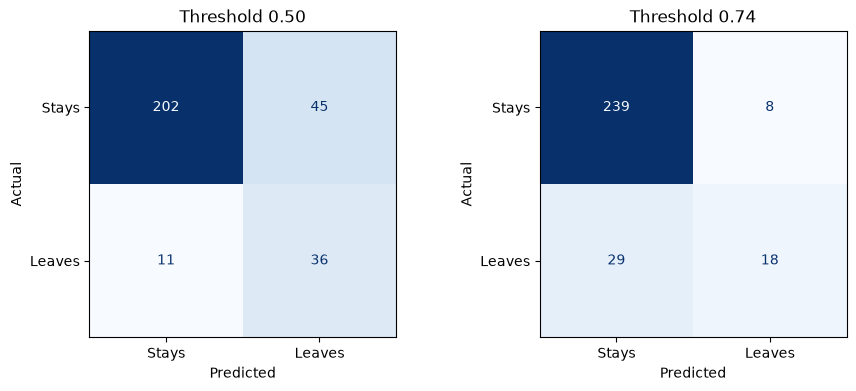

In [5]:
test_scores = final_pipeline.predict_proba(X_test)[:, 1]
print(f"PR-AUC:  {average_precision_score(y_test, test_scores):.3f} (chance: {y_test.mean():.3f})")
print(f"ROC-AUC: {roc_auc_score(y_test, test_scores):.3f} (chance: 0.500)\n")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
for ax, cutoff in zip(axes, [0.5, threshold]):
    predictions = (test_scores >= cutoff).astype(int)
    print(f"Threshold {cutoff:.2f}\n{classification_report(y_test, predictions, target_names=['Stays', 'Leaves'], digits=3)}")
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=["Stays", "Leaves"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set(title=f"Threshold {cutoff:.2f}", xlabel="Predicted", ylabel="Actual")
plt.show()

At the optimised threshold of 0.74, the model flags 26 employees. 18 of them actually left (69% precision), but it catches only 18 of 47 leavers (38% recall). At 0.5 it catches 36 of 47 leavers (77%) but raises 45 false alarms. Accuracy says little here, because always predicting "stays" already reaches 84%.

## 5. Conclusion

**Which ML algorithm did you choose and why?**
XGBoost, a gradient-boosted decision-tree model. It handles numeric and integer-coded categorical features without scaling, learns non-linear effects and supports class weights. A logistic regression would rank employees about as well. However, its coefficients already explain it, so LIME would add little. XGBoost cannot be read directly, and that is what LIME is for.

**What parameter settings did you use and why?**
The randomized search selected 541 trees with a learning rate of 0.082 and depth 1. The other settings are `min_child_weight` 1.2, `subsample` 0.70, `colsample_bytree` 0.76 and `reg_lambda` 7.7. On this small dataset, simple trees with strong regularisation worked best. `scale_pos_weight` = 5.19 addresses the class imbalance. The decision threshold of 0.74 maximises F1 on out-of-fold training predictions.

**Which train-test split did you use? Did you encounter problems?**
We used a stratified 80/20 split with `random_state=42`: 1,176 training employees (190 leavers) and 294 test employees (47 leavers). Problems:
- **Class imbalance:** always predicting "stays" already gives 84% accuracy, so we used PR-AUC and class weights.
- **Small test set:** each leaver moves recall by about 2 percentage points.
- **Threshold transfer:** the threshold chosen on the training data reached a recall of 51% there but only 38% on the test set.

**What is the performance of your model? Is it suitable for predicting/classifying employee attrition?**
On the test set the model reaches a PR-AUC of 0.60 (chance: 0.16) and a ROC-AUC of 0.82 (chance: 0.5). At the 0.74 threshold it catches 18 of 47 leavers with 8 false alarms. At 0.5 it catches 36 of 47 with 45 false alarms. The model is suitable for identifying groups with an elevated risk of leaving. It is not suitable for reliably predicting individual resignations.

**For management:** Can we reliably predict who will resign? Not for individual employees, but the model does find risk groups. 7 out of 10 of its alerts are correct, compared with fewer than 2 out of 10 for a random selection. It is useful as an early-warning list for retention conversations, but not for automated decisions about individual employees.